# 27. Case study: the October 29–30, 2026 Binance security incident and Bitcoin decline

If the frozen models (notebook 16 M0, M1 and M3 with the notebook 05 budget rule) had issued an alert in this decline, would it have come **before** the onset or while the decline was **in progress**?

- I use the models, thresholds and budget exactly as frozen and train or select nothing. I observed the event **before** the preregistration, so it is not part of the confirmatory test, and I do not use it to change the preregistered hypotheses.
- I identify events as in the paper (4% below the prior 240-minute high, held for 5 minutes). Because the decline may have lasted longer, I also examine a 24-hour window (Section 9.9).
- Data: verified Binance spot monthly archives for 2025-12 to 2026-09 and daily archives for 2026-10. For days not yet published as archives (usually the current and previous day) I take data from the Binance public market-data API and mark them as unverified (`source` column of `0_source_manifest.csv`).
- Signals (z_vol, tsr, z_hs): I recompute them with the notebook 01 formulas and compare them with the cache where the two overlap.
- Venue comparison: to see whether Binance prices moved on their own while withdrawals were halted, I compare Binance with Coinbase BTC-USD one-minute candles. Binance quotes in USDT and Coinbase in USD, so I also report a spread with the USDT rate removed using Coinbase USDT-USD one-minute candles. I split windows at event milestones (first peak; peak, 1% onset and 4% breach of the 240-minute event) and use the 7 days before the first peak as baseline.
- Stage decomposition (section 4b): I split the reason for a missing alert into **signal → judging window → cooldown → budget**. With the same scores and thresholds, I replay the alert rule as (a) the actual budget, (b) no monthly cap (240 per year and 240-minute spacing kept) and (c) 240-minute spacing only. Replays (b) and (c) are descriptive comparisons, not new rules.

This is a descriptive case study. I record the settings in `27_SPEC.json` and write the results to `case_oct2026_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
import joblib

OUT = SPOT_BASE / 'case_oct2026_v1'; OUT.mkdir(parents=True, exist_ok=True)
RAW27 = DRIVE / 'BTCUSDT_spot_2025_2026_case' / '1m'; RAW27.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
DNAME, DCL = '4pct', 0.04
MONTHS = month_list('2025-12', '2026-09')
DAYS = [d.strftime('%Y-%m-%d') for d in pd.date_range('2026-10-01', '2026-10-31', freq='D')]
NOW = pd.Timestamp.now(tz='UTC').floor('min')
CASE_START, CASE_END = ts('2026-10-28'), min(NOW, ts('2026-11-01'))
YEAR_START = ts('2026-01-01')
H_CASE = [240, 1440]
BINANCE_API_BASES = ['https://data-api.binance.vision', 'https://api.binance.com']
COINBASE_API = 'https://api.exchange.coinbase.com'
METHODS_CASE = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich']
for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebook 16 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')
SPEC = {'title': 'Case study: Binance security incident and Bitcoin decline, 2026-10-29/30 (descriptive)',
        'status': 'descriptive; observed before the pre-registration; not part of any confirmatory test; no model, threshold or rule is changed',
        'models': {m: 'notebook-16 frozen (2021 training, 2022 calibration)' for m in METHODS_CASE},
        'scheduler': 'notebook-5 calendar: 20/month, 240/yr, 240-min cooldown, run from 2026-01-01',
        'events': {'rule': 'notebook-2 price_only_catalog, 4% below the H-minute high, 5-close confirmation', 'H': H_CASE},
        'matching': 'paper rules: caught if an alert falls 30-240 min before the breach; pre-onset if before the 1% onset',
        'data': {'monthly': [MONTHS[0], MONTHS[-1]], 'daily': 'October 2026 daily archives; unpublished days from the public market-data API (marked unverified)',
                 'reference': 'Coinbase BTC-USD and USDT-USD 1m candles, if reachable'},
        'stage_decomposition': {'stages': ['signal: a score at or above the frozen threshold from 240 min before the peak to the breach',
                                           'window: a candidate minute 30-240 min before the breach (pre-onset part / in-progress part)',
                                           'cooldown: the cooldown-only replay emits an alert in the window',
                                           'budget: the actual budgeted replay emits an alert in the window'],
                                'replays': {'actual': '20/month, 240/yr, 240-min cooldown', 'no_monthly_cap': '240/yr, 240-min cooldown',
                                            'cooldown_only': '240-min cooldown'},
                                'note': 'replays (b) and (c) are descriptive comparisons, not rules; all start on 2026-01-01'},
        'venue_windows': {'baseline': '7 days before the first event peak (any H)',
                          'milestones': 'first peak, H=240 peak, H=240 1% onset, H=240 breach, breach + 240 min, data end',
                          'spread_bp': '1e4 * (Binance BTCUSDT / Coinbase BTC-USD - 1)',
                          'spread_usdt_adj_bp': '1e4 * (Binance BTCUSDT * Coinbase USDT-USD / Coinbase BTC-USD - 1); USDT-USD carried forward up to 30 min',
                          'flags': 'minutes above 25 bp (level); minutes more than 10 and 25 bp from the baseline median'},
        'case_window': [str(CASE_START), 'run time']}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
(OUT / '27_SPEC.json').write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16], '| run time', NOW)

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/case_oct2026_v1 | spec sha256 43ca7f998ad4ea06 | run time 2026-10-30 14:32:00+00:00


## 1. Data

In [2]:
def get_daily(symbol, days, dest):
    rows = []
    for d in days:
        if ts(d) >= NOW.floor('D') + pd.Timedelta(days=1):
            continue
        url = f'{BINANCE}spot/daily/klines/{symbol}/1m/{symbol}-1m-{d}.zip'; z = Path(dest) / f'{symbol}-1m-{d}.zip'
        chk = _fetch(url + '.CHECKSUM', tries=2)
        if chk is None:
            rows.append(dict(symbol=symbol, period=d, url=url, sha256=None, status='not_listed')); continue
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None or hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'daily archive missing or SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z); status = 'downloaded'
        rows.append(dict(symbol=symbol, period=d, url=url, sha256=expected, status=status))
    return pd.DataFrame(rows)


def _get_json(url, tries=3):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=60) as r:
                return json.loads(r.read().decode())
        except Exception as e:
            last = e; time.sleep(1 + k)
    raise RuntimeError(f'{url}: {last}')


def fetch_api_klines(symbol, start, end):
    """Public market-data klines [start, end), complete minutes only. Tries each base URL in turn."""
    errors = []
    for base in BINANCE_API_BASES:
        try:
            rows, cur, end_ms = [], int(start.value // 10**6), int(end.value // 10**6)
            while cur < end_ms:
                data = _get_json(f'{base}/api/v3/klines?symbol={symbol}&interval=1m&startTime={cur}&endTime={end_ms - 1}&limit=1000')
                new = [r for r in data if cur <= int(r[0]) < end_ms and int(r[0]) + 60000 <= int(NOW.value // 10**6)]
                if not new:
                    break
                rows += new; cur = int(new[-1][0]) + 60000; time.sleep(0.2)
            if not rows:
                raise RuntimeError('no rows returned')
            x = pd.DataFrame([r[:12] for r in rows], columns=RAW_COLS)
            z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
            z.index = pd.DatetimeIndex(pd.to_datetime(pd.to_numeric(x.open_time), unit='ms', utc=True), name='open_time')
            return z[~z.index.duplicated(keep='last')].sort_index().astype('float64'), base
        except Exception as e:
            errors.append(f'{base}: {e}')
    raise RuntimeError('public API unreachable: ' + ' | '.join(errors))


t_ = time.time()
man_m = get_archives('spot', 'BTCUSDT', MONTHS, RAW27)
man_d = get_daily('BTCUSDT', DAYS, RAW27)
parts = [parse_kline_zip(RAW27 / f'BTCUSDT-1m-{r.month}.zip') for r in man_m.itertuples()]
parts += [parse_kline_zip(RAW27 / f'BTCUSDT-1m-{r.period}.zip') for r in man_d.itertuples() if r.status != 'not_listed']
src = [dict(period=r.month, source='monthly archive (SHA-256 verified)', sha256=r.sha256) for r in man_m.itertuples()]
src += [dict(period=r.period, source='daily archive (SHA-256 verified)', sha256=r.sha256) for r in man_d.itertuples() if r.status != 'not_listed']
missing = [r.period for r in man_d.itertuples() if r.status == 'not_listed']
if missing:
    api_start = ts(missing[0]); api, api_base = fetch_api_klines('BTCUSDT', api_start, CASE_END)
    parts.append(api)
    for d in missing:
        src.append(dict(period=d, source=f'public API {api_base} (NOT verified; rerun after the daily archive is published)', sha256=None))
    print(f'{len(missing)} day(s) not yet in the daily archive ({missing[0]} -> {missing[-1]}): {len(api):,} minutes from {api_base}')
raw = pd.concat(parts).sort_index(kind='stable'); raw = raw[~raw.index.duplicated(keep='first')]   # verified archives win on overlap
last_min = raw.index.max()
px = regularize(raw, start=ts(MONTHS[0] + '-01'), end=last_min)
SRC = pd.DataFrame(src); SRC.to_csv(OUT / '0_source_manifest.csv', index=False); display(SRC.tail(8))
print(f'price grid {px.index.min()} -> {px.index.max()} ({len(px):,} minutes, {int(px.close.isna().sum())} NaN closes) in {time.time() - t_:.0f}s')

BTCUSDT spot {'cached': 10}
1 day(s) not yet in the daily archive (2026-10-30 -> 2026-10-30): 872 minutes from https://data-api.binance.vision


,period,source,sha256
32,2026-10-23,daily archive (SHA-256 verified),2055ad6a88a9f2995f6b1f52dde92dbe369f2ef518ee93...
33,2026-10-24,daily archive (SHA-256 verified),9c975443231b3bfb0ecbfd95e95d82e56c07a5a12d4319...
34,2026-10-25,daily archive (SHA-256 verified),021d02ee81337e933f048c056ee8aa9b8fa5648941fe68...
35,2026-10-26,daily archive (SHA-256 verified),b8fda506a4e729059e906808d274dc4abaade0b368aadd...
36,2026-10-27,daily archive (SHA-256 verified),37c4ecf92f7e00833cde74c5aa62bc217e2646fd0cfed0...
37,2026-10-28,daily archive (SHA-256 verified),8f8cef309938e78bea518a4df2fff9b5822ca88ff92033...
38,2026-10-29,daily archive (SHA-256 verified),c86586d5773b5663d311e4969503228ad07b41b5c78629...
39,2026-10-30,public API https://data-api.binance.vision (NO...,None


price grid 2025-12-01 00:00:00+00:00 -> 2026-10-30 14:31:00+00:00 (480,392 minutes, 0 NaN closes) in 37s


## 2. Signal recomputation, cache comparison and reproduction of the frozen models

In [3]:
t_ = time.time()
sg = compute_spot_features(px)
pxc, sgc = load_btc_spot()
ov = pxc.index[(pxc.index >= ts('2026-01-15')) & (pxc.index <= min(pxc.index.max(), px.index.max()))]
if len(ov) < 30 * 1440:
    raise RuntimeError('GUARD FAIL: too little overlap with the spot cache to verify the signal pipeline')
for col in ['close', 'volume', 'taker_buy_vol']:          # same checks and tolerances as notebook 11
    a_ = px.loc[ov, col].to_numpy(float); b_ = pxc.loc[ov, col].to_numpy(float); both = np.isfinite(a_) & np.isfinite(b_)
    if (np.isfinite(a_) != np.isfinite(b_)).any() or not np.array_equal(a_[both], b_[both]):
        raise RuntimeError(f'GUARD FAIL: archive {col} differs from the spot cache on the overlap')
for col, tol in [('z_vol', 5e-4), ('tsr', 5e-6), ('z_hs', 5e-4)]:
    a_ = sg.loc[ov, col].to_numpy(float); b_ = sgc.loc[ov, col].to_numpy(float); both = np.isfinite(a_) & np.isfinite(b_)
    md = float(np.max(np.abs(a_[both] - b_[both]))) if both.any() else np.inf
    if (np.isfinite(a_) != np.isfinite(b_)).mean() > 1e-4 or md > tol:
        raise RuntimeError(f'GUARD FAIL: recomputed {col} differs from the spot cache (max |diff| {md:.3g})')
print(f'PASS: prices and signals equal the spot cache on {ov[0]:%Y-%m-%d} -> {ov[-1]:%Y-%m-%d}')

# M0 refit on the cache must reproduce notebook 16; M1 and M3 come straight from the frozen files.
Tc = pxc.index.asi8; vc = sgc.z_vol.to_numpy(float); fc = sgc.tsr.to_numpy(float); hc = sgc.z_hs.to_numpy(float)
Vc = (np.isfinite(pxc.close.to_numpy()) & (pxc.close.to_numpy() > 0) & np.isfinite(pxc.volume.to_numpy()) & (pxc.volume.to_numpy() > 0)
      & np.isfinite(vc) & np.isfinite(fc) & np.isfinite(hc) & (fc >= 0) & (fc <= 1))
Ec = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
Xc = np.column_stack([vc, fc]); okl = train_mask(Tc, Vc) & np.isfinite(Xc).all(axis=1)
m0 = new_logit().fit(Xc[okl], label_from_catalog(Tc, Ec)[okl]); cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']
if sha256_file(SPOT_BASE / cfg3['model_file']) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(SPOT_BASE / cfg3['model_file'])
TH = {m: float(FROZEN16['configs'][f'{m}|{DNAME}']['threshold_2022']) for m in METHODS_CASE}
del pxc, sgc, Tc, vc, fc, hc, Vc, Xc
print(f'PASS: M0 reproduces notebook 16; GBM file verified ({time.time() - t_:.0f}s); thresholds {TH}')

FFT computation 100,031/480,392
FFT computation 480,392/480,392
PASS: prices and signals equal the spot cache on 2026-01-15 -> 2026-04-30
PASS: M0 reproduces notebook 16; GBM file verified (15s); thresholds {'M0_VF_logit': 0.6698990591069133, 'M1_vol_threshold': 1.6760284010320905, 'M3_GBM_rich': 0.11353132038571002}


## 3. 2026 scores and budgeted alerts (same rule from January 1)

In [4]:
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
F = causal_features(px, sg)
S = {}
Xl = np.column_stack([v_, f_]); okp = VALID & np.isfinite(Xl).all(axis=1)
s = np.full(len(T), np.nan); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[VALID] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[VALID])[:, 1]; S['M3_GBM_rich'] = s
Y26 = VALID & (T >= YEAR_START.value)
ALR = {m: emit_calendar_fast(T[Y26 & np.isfinite(S[m])], S[m][Y26 & np.isfinite(S[m])] >= TH[m]) for m in METHODS_CASE}
for m in METHODS_CASE:
    a = pd.to_datetime(ALR[m], utc=True)
    oct_before = int(((a >= ts('2026-10-01')) & (a < CASE_START)).sum())
    print(f'{m:18s} 2026 alerts {len(a):4d} | October before {CASE_START:%m-%d}: {oct_before:2d} of the monthly cap {MONTH_CAP} '
          f'| alerts in the case window: {int((a >= CASE_START).sum())}')

M0_VF_logit        2026 alerts  200 | October before 10-28: 20 of the monthly cap 20 | alerts in the case window: 0
M1_vol_threshold   2026 alerts  200 | October before 10-28: 20 of the monthly cap 20 | alerts in the case window: 0
M3_GBM_rich        2026 alerts  192 | October before 10-28: 20 of the monthly cap 20 | alerts in the case window: 0


## 4. Event identification and alert matching

- `caught`: an alert 30–240 minutes before the crash; `pre-onset` if it came before the 1% onset, otherwise in progress.
- `first candidate`: the first minute at which the score crossed the threshold regardless of budget (from 240 minutes before the event peak to the crash); it shows whether the budget blocked an alert.

In [5]:
def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


DD240 = 1 - px.close / px.close.rolling(240, min_periods=120).max()
w = (px.index >= CASE_START) & (px.index < CASE_END)
dd_max = float(DD240[w].max()); dd_at = DD240[w].idxmax()
low_at = px.close[w].idxmin(); hi24 = px.close[w].rolling(1440, min_periods=1).max()
print(f'case window {CASE_START:%Y-%m-%d %H:%M} -> {px.index[w][-1]:%Y-%m-%d %H:%M} UTC | largest fall below the 240-min high: {100 * dd_max:.2f}% at {dd_at:%m-%d %H:%M} '
      f'| lowest close at {low_at:%m-%d %H:%M} | fall from the prior 24-h high at that minute: {100 * (1 - px.close[low_at] / hi24[low_at]):.2f}%')

rows = []; EVC = {}
for H in H_CASE:
    E_ = catalog_H(H); ev = E_[(E_.breach_utc >= CASE_START) & (E_.breach_utc < CASE_END)].reset_index(drop=True); EVC[H] = ev
    n_oct = int(((E_.breach_utc >= ts('2026-10-01')) & (E_.breach_utc < CASE_END)).sum())
    print(f'H = {H} min: {n_oct} event(s) in October 2026, {len(ev)} in the case window')
    for e in ev.itertuples():
        base = dict(H=H, event_id=int(e.event_id), peak_utc=e.peak_utc, onset_utc=e.onset_1pct_utc, breach_utc=e.breach_utc, confirmed_utc=e.confirmed_utc,
                    peak_to_onset_min=(e.onset_1pct_utc - e.peak_utc).total_seconds() / 60, onset_to_breach_min=(e.breach_utc - e.onset_1pct_utc).total_seconds() / 60)
        for m in METHODS_CASE:
            mm = match_events(ev[ev.event_id == e.event_id], ALR[m])
            al = pd.to_datetime(ALR[m], utc=True); near = al[(al >= e.peak_utc - pd.Timedelta(minutes=LEAD_MAX)) & (al <= e.confirmed_utc + pd.Timedelta(hours=6))]
            ii = (T >= (e.peak_utc - pd.Timedelta(minutes=LEAD_MAX)).value) & (T <= e.breach_utc.value) & np.isfinite(S[m]) & (S[m] >= TH[m])
            fc_ = pd.Timestamp(T[ii][0], tz='UTC') if ii.any() else pd.NaT
            rel = lambda t: (t - e.onset_1pct_utc).total_seconds() / 60 if pd.notna(t) else np.nan
            rows.append(dict(**base, method=m, caught=len(mm) > 0,
                             endpoint=('pre-onset' if bool(mm.pre1pct.iloc[0]) else 'in-progress') if len(mm) else 'not caught',
                             matched_alert_utc=mm.alarm_utc.iloc[0] if len(mm) else pd.NaT,
                             matched_alert_min_from_onset=rel(mm.alarm_utc.iloc[0]) if len(mm) else np.nan,
                             matched_alert_min_before_breach=float(mm.lead_min.iloc[0]) if len(mm) else np.nan,
                             first_candidate_utc=fc_, first_candidate_min_from_onset=rel(fc_),
                             first_candidate_before_peak=bool(pd.notna(fc_) and fc_ < e.peak_utc),
                             alerts_near_event=', '.join(f'{t:%m-%d %H:%M}' for t in near)))
CASE = pd.DataFrame(rows); CASE.to_csv(OUT / '1_case_events_alerts.csv', index=False)
for H, ev in EVC.items():
    ev[['event_id', 'peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc', 'peak_to_breach_minutes', 'onset_to_breach_minutes']].to_csv(
        OUT / f'2_events_H{H}.csv', index=False)          # timestamps only, no prices
if len(CASE):
    display(CASE[['H', 'method', 'peak_utc', 'onset_utc', 'breach_utc', 'endpoint', 'matched_alert_utc', 'matched_alert_min_from_onset',
                  'first_candidate_utc', 'first_candidate_min_from_onset', 'alerts_near_event']])
else:
    print('No 4% event (240-min or 24-h window) in the case window; see the largest-fall line above.')

case window 2026-10-28 00:00 -> 2026-10-30 14:31 UTC | largest fall below the 240-min high: 4.34% at 10-30 00:26 | lowest close at 10-30 02:04 | fall from the prior 24-h high at that minute: 6.48%
H = 240 min: 1 event(s) in October 2026, 1 in the case window
H = 1440 min: 4 event(s) in October 2026, 1 in the case window


,H,method,peak_utc,onset_utc,breach_utc,endpoint,matched_alert_utc,matched_alert_min_from_onset,first_candidate_utc,first_candidate_min_from_onset,alerts_near_event
0,240,M0_VF_logit,2026-10-29 20:31:00+00:00,2026-10-29 20:41:00+00:00,2026-10-30 00:21:00+00:00,not caught,NaT,NaN,2026-10-29 20:09:00+00:00,-32.0,
1,240,M1_vol_threshold,2026-10-29 20:31:00+00:00,2026-10-29 20:41:00+00:00,2026-10-30 00:21:00+00:00,not caught,NaT,NaN,2026-10-29 20:08:00+00:00,-33.0,
2,240,M3_GBM_rich,2026-10-29 20:31:00+00:00,2026-10-29 20:41:00+00:00,2026-10-30 00:21:00+00:00,not caught,NaT,NaN,2026-10-29 20:06:00+00:00,-35.0,
3,1440,M0_VF_logit,2026-10-29 16:08:00+00:00,2026-10-29 17:07:00+00:00,2026-10-29 23:38:00+00:00,not caught,NaT,NaN,2026-10-29 13:42:00+00:00,-205.0,
4,1440,M1_vol_threshold,2026-10-29 16:08:00+00:00,2026-10-29 17:07:00+00:00,2026-10-29 23:38:00+00:00,not caught,NaT,NaN,2026-10-29 13:46:00+00:00,-201.0,
5,1440,M3_GBM_rich,2026-10-29 16:08:00+00:00,2026-10-29 17:07:00+00:00,2026-10-29 23:38:00+00:00,not caught,NaT,NaN,2026-10-29 20:06:00+00:00,179.0,


## 4b. Stage decomposition: signal → judging window → cooldown → budget

Here I change only the alert rule and replay it from January 1, 2026 with the same frozen scores and thresholds. This is a descriptive comparison of the stage at which an alert was blocked, not a new rule.

| Stage | Passed if |
|---|---|
| 1. Signal | some minute from 240 minutes before the peak to the crash has a score at or above the threshold |
| 2. Judging window | such a minute lies 30–240 minutes before the crash (pre-onset part / in-progress part) |
| 3. Cooldown | the cooldown-only rule (`cooldown_only`) emits an alert inside the judging window |
| 4. Budget | the actual rule (`actual`: 20 per month, 240 per year, 240 minutes) emits an alert inside the judging window |

`failed_at`: the first stage not passed. `actual_block_reasons`: counts of why the actual rule blocked candidate minutes inside the judging window (monthly cap, annual cap, cooldown).

In [6]:
POLICIES = {'actual': dict(B=B, cap=MONTH_CAP), 'no_monthly_cap': dict(B=B, cap=10**9), 'cooldown_only': dict(B=10**9, cap=10**9)}


def replay_calendar(t, elig, B_, cap_, cooldown_min=COOLDOWN_MIN):
    """Python replay of the notebook-5 calendar rule. Returns the alerts and, for every candidate minute, the binding
    constraints when it was not emitted (bit 1 annual cap, 2 monthly cap, 4 cooldown; 0 = emitted) and the last alert before it."""
    years, months = cal_fields(t)
    idx = np.flatnonzero(elig); reason = np.zeros(len(idx), np.int8); prev = np.full(len(idx), -1, np.int64)
    out = []; mcount = ycount = 0; pm = py = -1; last = -(2**62); cd = np.int64(cooldown_min * NS)
    for k, i in enumerate(idx):
        if years[i] != py:
            ycount = 0; py = years[i]
        if months[i] != pm:
            mcount = 0; pm = months[i]
        r = (1 if ycount >= B_ else 0) | (2 if mcount >= cap_ else 0) | (4 if t[i] - last < cd else 0)
        prev[k] = last if last > -(2**62) else -1
        if r:
            reason[k] = r; continue
        out.append(t[i]); last = t[i]; ycount += 1; mcount += 1
    return np.asarray(out, np.int64), idx, reason, prev


def reason_text(r):
    return '+'.join(n for b, n in [(1, 'annual cap'), (2, 'monthly cap'), (4, 'cooldown')] if r & b) or 'emitted'


RP = {}                                    # (method, policy) -> (alerts, candidate index, reasons, previous alert)
for m in METHODS_CASE:
    ok_ = Y26 & np.isfinite(S[m]); tt = T[ok_]; el = S[m][ok_] >= TH[m]
    for p, kw in POLICIES.items():
        a_, ix_, rs_, pv_ = replay_calendar(tt, el, kw['B'], kw['cap'])
        if not np.array_equal(a_, emit_calendar_fast(tt, el, B=kw['B'], cap=kw['cap'])):
            raise RuntimeError(f'GUARD FAIL: replay differs from the compiled calendar ({m}, {p})')
        RP[(m, p)] = (a_, tt[ix_], rs_, pv_)
    if not np.array_equal(RP[(m, 'actual')][0], ALR[m]):
        raise RuntimeError(f'GUARD FAIL: actual replay differs from section 3 ({m})')
print('PASS: the Python replay reproduces the compiled calendar for every method and policy')
for m in METHODS_CASE:
    print(f'{m:18s} 2026 alerts: ' + ', '.join(f'{p} {len(RP[(m, p)][0])}' for p in POLICIES)
          + ' | October alerts before the case: ' + ', '.join(f'{p} {int(((RP[(m, p)][0] >= ts("2026-10-01").value) & (RP[(m, p)][0] < CASE_START.value)).sum())}' for p in POLICIES))

fmt = lambda v: pd.Timestamp(int(v), tz='UTC').strftime('%m-%d %H:%M')
srows, prows = [], []
for H, ev in EVC.items():
    for e in ev.itertuples():
        on, br, pk = e.onset_1pct_utc.value, e.breach_utc.value, e.peak_utc.value
        w0, w1 = br - LEAD_MAX * NS, br - LEAD_MIN * NS                     # matching window, both ends included
        rel = lambda v: (v - on) / NS
        for m in METHODS_CASE:
            cand = (T >= pk - LEAD_MAX * NS) & (T <= br) & np.isfinite(S[m]) & (S[m] >= TH[m])
            inw = cand & (T >= w0) & (T <= w1); pre = inw & (T < on); inn = inw & (T >= on)
            a_, tc, rs, pv = RP[(m, 'actual')]; sel_ = (tc >= w0) & (tc <= w1)
            reasons = pd.Series([reason_text(r) for r in rs[sel_]]).value_counts().to_dict() if sel_.any() else {}
            caught = {}
            for p in POLICIES:
                al = RP[(m, p)][0]; mm = match_events(ev[ev.event_id == e.event_id], al)
                near = al[(al >= pk - LEAD_MAX * NS) & (al <= e.confirmed_utc.value + 6 * 60 * NS)]
                caught[p] = len(mm) > 0
                prows.append(dict(H=H, event_id=int(e.event_id), method=m, policy=p, caught=len(mm) > 0,
                                  endpoint=('pre-onset' if bool(mm.pre1pct.iloc[0]) else 'in-progress') if len(mm) else 'not caught',
                                  matched_alert_utc=mm.alarm_utc.iloc[0] if len(mm) else pd.NaT,
                                  matched_min_from_onset=rel(mm.alarm_utc.iloc[0].value) if len(mm) else np.nan,
                                  matched_min_before_breach=float(mm.lead_min.iloc[0]) if len(mm) else np.nan,
                                  alerts_near_event=', '.join(fmt(v) for v in near),
                                  alerts_2026=len(al), october_alerts_before_case=int(((al >= ts('2026-10-01').value) & (al < CASE_START.value)).sum())))
            a_c, tc_c, rs_c, pv_c = RP[(m, 'cooldown_only')]; selc = (tc_c >= w0) & (tc_c <= w1)
            cd_from = sorted({fmt(v) for v, r in zip(pv_c[selc], rs_c[selc]) if r & 4 and v >= 0})
            failed_at = ('caught' if caught['actual'] else '1 signal' if not cand.any() else '2 window' if not inw.any()
                         else '3 cooldown' if not caught['cooldown_only'] else '4 budget')
            srows.append(dict(H=H, event_id=int(e.event_id), method=m, window_utc=f'{fmt(w0)} -> {fmt(w1)}',
                              pre_onset_minutes_possible=int(max(0, (min(on, w1 + NS) - w0) // NS)),
                              signal_minutes=int(cand.sum()), first_signal_min_from_onset=rel(T[cand][0]) if cand.any() else np.nan,
                              last_signal_min_from_onset=rel(T[cand][-1]) if cand.any() else np.nan,
                              window_candidates_pre_onset=int(pre.sum()), window_candidates_in_progress=int(inn.sum()),
                              first_pre_onset_candidate_min_from_onset=rel(T[pre][0]) if pre.any() else np.nan,
                              first_in_progress_candidate_min_from_onset=rel(T[inn][0]) if inn.any() else np.nan,
                              actual_block_reasons='; '.join(f'{k} {v}' for k, v in reasons.items()),
                              cooldown_only_blocked_by_alert_at=', '.join(cd_from), failed_at=failed_at,
                              **{f'caught_{p}': caught[p] for p in POLICIES}))
STAGE = pd.DataFrame(srows); POL = pd.DataFrame(prows)
STAGE.to_csv(OUT / '5a_stage_decomposition.csv', index=False); POL.to_csv(OUT / '5b_policy_replays.csv', index=False)
if len(STAGE):
    display(STAGE[['H', 'method', 'window_utc', 'pre_onset_minutes_possible', 'signal_minutes', 'window_candidates_pre_onset', 'window_candidates_in_progress',
                   'first_in_progress_candidate_min_from_onset', 'actual_block_reasons', 'cooldown_only_blocked_by_alert_at', 'failed_at']])
    display(POL[['H', 'method', 'policy', 'endpoint', 'matched_alert_utc', 'matched_min_from_onset', 'matched_min_before_breach', 'alerts_near_event', 'alerts_2026']])

# Per-minute scores (no prices) for the case window
cw = (T >= CASE_START.value)
MIN = pd.DataFrame({'utc': pd.to_datetime(T[cw], utc=True)})
for m in METHODS_CASE:
    MIN[f'{m}_score'] = S[m][cw]; MIN[f'{m}_over_threshold'] = S[m][cw] / TH[m]; MIN[f'{m}_candidate'] = np.isfinite(S[m][cw]) & (S[m][cw] >= TH[m])
    for p in POLICIES:
        MIN[f'{m}_alert_{p}'] = np.isin(T[cw], RP[(m, p)][0])
MIN.to_csv(OUT / '6_case_minutes_scores.csv', index=False)

PASS: the Python replay reproduces the compiled calendar for every method and policy
M0_VF_logit        2026 alerts: actual 200, no_monthly_cap 240, cooldown_only 381 | October alerts before the case: actual 20, no_monthly_cap 0, cooldown_only 31
M1_vol_threshold   2026 alerts: actual 200, no_monthly_cap 240, cooldown_only 356 | October alerts before the case: actual 20, no_monthly_cap 0, cooldown_only 28
M3_GBM_rich        2026 alerts: actual 192, no_monthly_cap 240, cooldown_only 378 | October alerts before the case: actual 20, no_monthly_cap 0, cooldown_only 20


,H,method,window_utc,pre_onset_minutes_possible,signal_minutes,window_candidates_pre_onset,window_candidates_in_progress,first_in_progress_candidate_min_from_onset,actual_block_reasons,cooldown_only_blocked_by_alert_at,failed_at
0,240,M0_VF_logit,10-29 20:21 -> 10-29 23:51,20,196,20,134,0.0,monthly cap 154,10-29 20:09,3 cooldown
1,240,M1_vol_threshold,10-29 20:21 -> 10-29 23:51,20,197,20,134,0.0,monthly cap 154,10-29 20:08,3 cooldown
2,240,M3_GBM_rich,10-29 20:21 -> 10-29 23:51,20,220,2,184,0.0,monthly cap 186,10-29 20:06,3 cooldown
3,1440,M0_VF_logit,10-29 19:38 -> 10-29 23:08,0,200,0,160,182.0,monthly cap 160,10-29 20:09,4 budget
4,1440,M1_vol_threshold,10-29 19:38 -> 10-29 23:08,0,200,0,161,181.0,monthly cap 161,10-29 20:08,4 budget
5,1440,M3_GBM_rich,10-29 19:38 -> 10-29 23:08,0,177,0,147,179.0,monthly cap 147,10-29 20:06,4 budget


,H,method,policy,endpoint,matched_alert_utc,matched_min_from_onset,matched_min_before_breach,alerts_near_event,alerts_2026
0,240,M0_VF_logit,actual,not caught,NaT,NaN,NaN,,200
1,240,M0_VF_logit,no_monthly_cap,not caught,NaT,NaN,NaN,,240
2,240,M0_VF_logit,cooldown_only,not caught,NaT,NaN,NaN,"10-29 20:09, 10-30 00:09",381
3,240,M1_vol_threshold,actual,not caught,NaT,NaN,NaN,,200
4,240,M1_vol_threshold,no_monthly_cap,not caught,NaT,NaN,NaN,,240
5,240,M1_vol_threshold,cooldown_only,not caught,NaT,NaN,NaN,"10-29 20:08, 10-30 00:08",356
6,240,M3_GBM_rich,actual,not caught,NaT,NaN,NaN,,192
7,240,M3_GBM_rich,no_monthly_cap,not caught,NaT,NaN,NaN,,240
8,240,M3_GBM_rich,cooldown_only,not caught,NaT,NaN,NaN,"10-29 20:06, 10-30 00:06",378
9,1440,M0_VF_logit,actual,not caught,NaT,NaN,NaN,,200


## 5. Venue comparison: did Binance prices move on their own while withdrawals were halted? (Coinbase BTC-USD, USDT-USD)

I split windows at event milestones and use the 7 days before the first peak as baseline. `spread_usdt_adj_bp` removes the USDT/USD rate and so comes closer to a difference specific to the Binance venue.

In [7]:
def fetch_coinbase(start, end, product='BTC-USD'):
    rows, cur = [], start
    while cur < end:
        nxt = min(cur + pd.Timedelta(minutes=300), end)
        rows += _get_json(f'{COINBASE_API}/products/{product}/candles?granularity=60&start={cur:%Y-%m-%dT%H:%M:%SZ}&end={nxt:%Y-%m-%dT%H:%M:%SZ}')
        cur = nxt; time.sleep(0.35)
    cb = pd.DataFrame(rows, columns=['time', 'low', 'high', 'open', 'close', 'volume']).drop_duplicates('time')
    cb.index = pd.to_datetime(cb.time, unit='s', utc=True); return cb.sort_index()


def spread_stats(x, base_med):
    x = x.dropna()
    if not len(x):
        return dict(minutes=0)
    d = x - base_med
    return dict(minutes=len(x), median=float(x.median()), p90=float(x.quantile(.9)), min=float(x.min()), max=float(x.max()),
                max_at=str(x.idxmax()), minutes_above_25bp=int((x > 25).sum()), median_minus_baseline=float(x.median() - base_med),
                minutes_dev_over_10bp=int(d.abs().gt(10).sum()), minutes_dev_over_25bp=int(d.abs().gt(25).sum()))


ALL_EV = pd.concat([ev.assign(H=H) for H, ev in EVC.items()]) if any(len(ev) for ev in EVC.values()) else pd.DataFrame()
P0 = ALL_EV.peak_utc.min() if len(ALL_EV) else CASE_START
MS = [('first peak - 7d', P0 - pd.Timedelta(days=7)), ('first peak', P0)]
if 240 in EVC and len(EVC[240]):
    e240 = EVC[240].iloc[0]
    MS += [('H240 peak', e240.peak_utc), ('H240 onset', e240.onset_1pct_utc), ('H240 breach', e240.breach_utc),
           ('H240 breach + 4h', e240.breach_utc + pd.Timedelta(minutes=240))]
MS += [('data end', px.index.max() + pd.Timedelta(minutes=1))]
MS = sorted({t: n for n, t in MS}.items())                     # unique times, in order
REF = None; VW = VD = None
try:
    cb = fetch_coinbase(MS[0][0], MS[-1][0])
    j = pd.DataFrame({'binance': px.close, 'coinbase': cb.close}).dropna(); j = j[j.index >= MS[0][0]]
    j['spread_bp'] = 1e4 * (j.binance / j.coinbase - 1)
    try:
        cu = fetch_coinbase(MS[0][0], MS[-1][0], 'USDT-USD')
        usdt = cu.close.reindex(pd.date_range(MS[0][0], MS[-1][0], freq='min', inclusive='left')).ffill(limit=30)
        j['usdt_usd_bp'] = 1e4 * (usdt.reindex(j.index) - 1)
        j['spread_usdt_adj_bp'] = 1e4 * (j.binance * usdt.reindex(j.index) / j.coinbase - 1)
    except Exception as e:
        print(f'Coinbase USDT-USD unavailable ({type(e).__name__}: {str(e)[:120]}); USDT-adjusted spread skipped.')
    cols = [c for c in ['spread_bp', 'spread_usdt_adj_bp'] if c in j]
    base = j[(j.index >= MS[0][0]) & (j.index < MS[1][0])]; bmed = {c: float(base[c].median()) for c in cols}
    vw = []
    for (t0_, n0), (t1_, n1) in zip(MS[:-1], MS[1:]):
        x = j[(j.index >= t0_) & (j.index < t1_)]
        row = dict(window=f'{n0} -> {n1}', start_utc=str(t0_), end_utc=str(t1_))
        for c in cols:
            row.update({f'{c}_{k}': v for k, v in spread_stats(x[c], bmed[c]).items()})
        if 'usdt_usd_bp' in j:
            row['usdt_usd_bp_median'] = float(x.usdt_usd_bp.median()) if x.usdt_usd_bp.notna().any() else np.nan
        vw.append(row)
    VW = pd.DataFrame(vw)
    vd = []
    for d_, x in j.groupby(j.index.floor('D')):
        row = dict(utc_day=f'{d_:%Y-%m-%d}')
        for c in cols:
            row.update({f'{c}_{k}': v for k, v in spread_stats(x[c], bmed[c]).items() if k in ('minutes', 'median', 'max', 'minutes_above_25bp', 'minutes_dev_over_10bp')})
        vd.append(row)
    VD = pd.DataFrame(vd)
    VW.to_csv(OUT / '3b_spread_by_window.csv', index=False); VD.to_csv(OUT / '3c_spread_by_utc_day.csv', index=False)
    j.to_csv(OUT / '3_binance_vs_coinbase_spread.csv', columns=[c for c in ['spread_bp', 'usdt_usd_bp', 'spread_usdt_adj_bp'] if c in j])   # spreads only, no prices
    REF = dict(baseline_window=[str(MS[0][0]), str(MS[1][0])], baseline_median_bp=bmed, minutes_compared=len(j),
               usdt_minutes_covered=int(j['spread_usdt_adj_bp'].notna().sum()) if 'spread_usdt_adj_bp' in j else 0,
               windows=VW.to_dict('records'), by_utc_day=VD.to_dict('records'),
               coinbase_fall_from_24h_high_at_binance_low_pct=float(100 * (1 - cb.close.reindex([low_at]).iloc[0] / cb.close[:low_at].tail(1440).max()))
               if low_at in cb.index else None)
    show_ = ['window'] + [f'{c}_{k}' for c in cols for k in ('median', 'max', 'minutes_above_25bp', 'median_minus_baseline', 'minutes_dev_over_10bp')]
    print('baseline median (bp):', {k: round(v, 2) for k, v in bmed.items()}); display(VW[[c for c in show_ if c in VW]].round(2)); display(VD.round(2))
except Exception as e:
    print(f'Coinbase reference unavailable ({type(e).__name__}: {str(e)[:200]}); venue comparison skipped.')

baseline median (bp): {'spread_bp': 14.23, 'spread_usdt_adj_bp': 0.93}


,window,spread_bp_median,spread_bp_max,spread_bp_minutes_above_25bp,spread_bp_median_minus_baseline,spread_bp_minutes_dev_over_10bp,spread_usdt_adj_bp_median,spread_usdt_adj_bp_max,spread_usdt_adj_bp_minutes_above_25bp,spread_usdt_adj_bp_median_minus_baseline,spread_usdt_adj_bp_minutes_dev_over_10bp
0,first peak - 7d -> first peak,14.23,21.80,0,0.00,0,0.93,8.88,0,0.00,0
1,first peak -> H240 peak,11.92,14.46,0,-2.31,0,1.04,3.07,0,0.11,0
2,H240 peak -> H240 onset,11.81,13.83,0,-2.43,0,-0.21,1.71,0,-1.14,0
3,H240 onset -> H240 breach,18.95,31.11,29,4.72,42,1.86,8.66,0,0.93,0
4,H240 breach -> H240 breach + 4h,26.31,29.97,198,12.08,213,4.94,8.37,0,4.01,0
5,H240 breach + 4h -> data end,20.27,29.71,112,6.03,131,4.35,11.46,0,3.42,1


,utc_day,spread_bp_minutes,spread_bp_median,spread_bp_max,spread_bp_minutes_above_25bp,spread_bp_minutes_dev_over_10bp,spread_usdt_adj_bp_minutes,spread_usdt_adj_bp_median,spread_usdt_adj_bp_max,spread_usdt_adj_bp_minutes_above_25bp,spread_usdt_adj_bp_minutes_dev_over_10bp
0,2026-10-22,472,13.67,15.91,0,0,472,0.68,3.78,0,0
1,2026-10-23,1440,13.68,19.18,0,0,1440,0.66,5.95,0,0
2,2026-10-24,1440,13.64,21.80,0,0,1440,0.72,8.88,0,0
3,2026-10-25,1440,13.68,15.97,0,0,1440,0.59,3.25,0,0
4,2026-10-26,1440,16.32,21.66,0,0,1440,1.22,5.76,0,0
5,2026-10-27,1440,17.35,20.73,0,0,1440,1.19,4.08,0,0
6,2026-10-28,1440,14.94,18.94,0,0,1440,1.18,4.64,0,0
7,2026-10-29,1440,14.00,29.15,18,29,1440,1.22,8.66,0,0
8,2026-10-30,872,22.63,31.11,321,357,872,4.52,11.46,0,1


## 6. Figures and summary

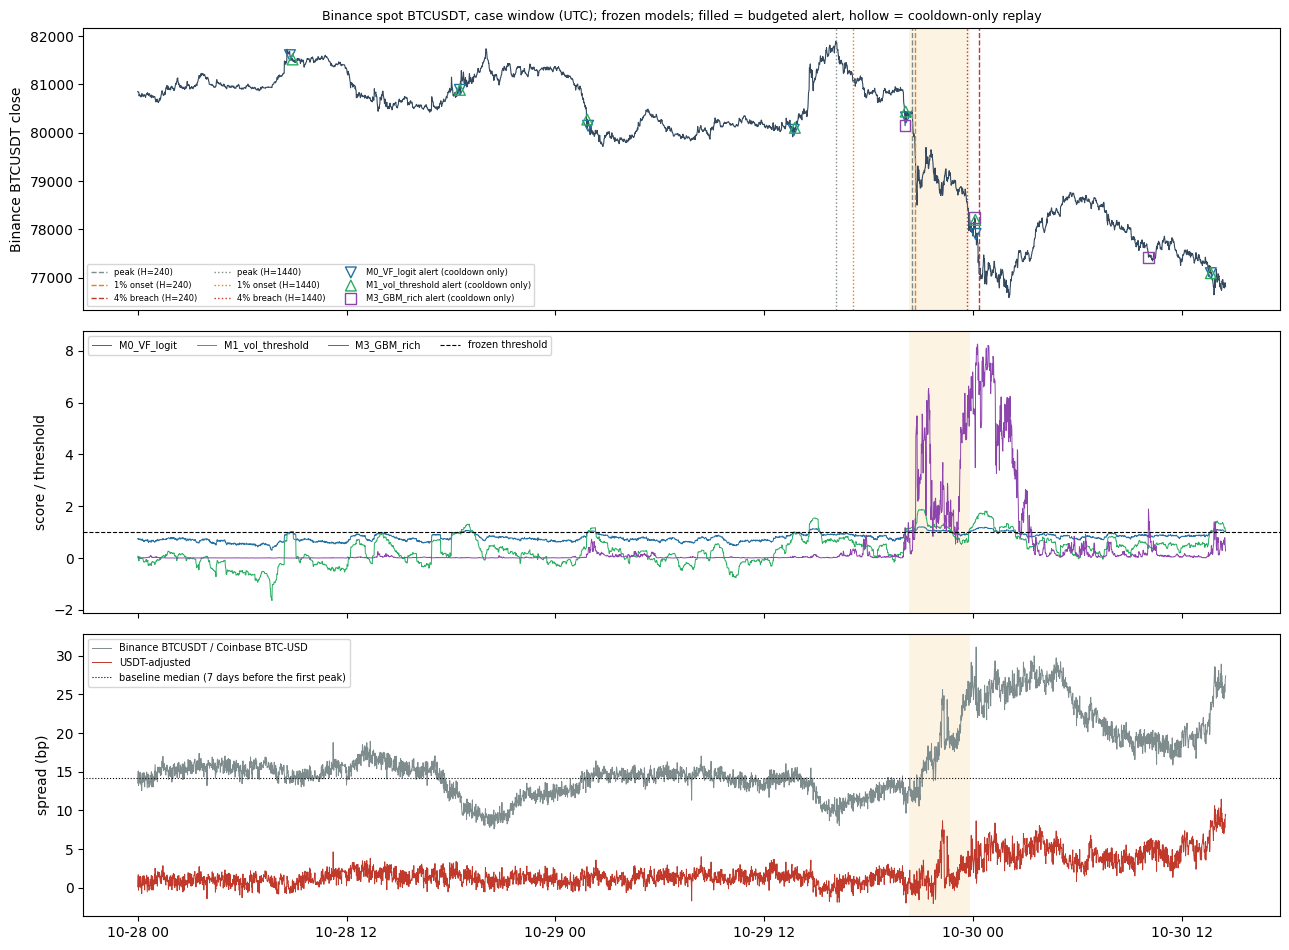

data through 2026-10-30 14:31:00+00:00 | unverified days: ['2026-10-30']
H= 240 M0_VF_logit        breach 10-30 00:21 (onset 20:41, peak 20:31) -> not caught  | first candidate -32 min from onset (before the peak)
H= 240 M1_vol_threshold   breach 10-30 00:21 (onset 20:41, peak 20:31) -> not caught  | first candidate -33 min from onset (before the peak)
H= 240 M3_GBM_rich        breach 10-30 00:21 (onset 20:41, peak 20:31) -> not caught  | first candidate -35 min from onset (before the peak)
H=1440 M0_VF_logit        breach 10-29 23:38 (onset 17:07, peak 16:08) -> not caught  | first candidate -205 min from onset (before the peak)
H=1440 M1_vol_threshold   breach 10-29 23:38 (onset 17:07, peak 16:08) -> not caught  | first candidate -201 min from onset (before the peak)
H=1440 M3_GBM_rich        breach 10-29 23:38 (onset 17:07, peak 16:08) -> not caught  | first candidate +179 min from onset
H= 240 M0_VF_logit        window 10-29 20:21 -> 10-29 23:51 | pre-onset minutes possible  20 | c

In [8]:
z0 = CASE_START; z1 = px.index.max()
sel = (px.index >= z0) & (px.index <= z1)
nrow = 3 if REF is not None else 2
fig, ax = plt.subplots(nrow, 1, figsize=(13, 3.2 * nrow), sharex=True)
ax[0].plot(px.index[sel], px.close[sel], color='#34495e', lw=0.8)
for H, ev in EVC.items():
    for e in ev.itertuples():
        for t, c, lab in [(e.peak_utc, '#7f8c8d', 'peak'), (e.onset_1pct_utc, '#e67e22', '1% onset'), (e.breach_utc, '#c0392b', '4% breach')]:
            ax[0].axvline(t, color=c, ls='--' if H == 240 else ':', lw=1, label=f'{lab} (H={H})')
mk = {'M0_VF_logit': ('v', '#2471a3'), 'M1_vol_threshold': ('^', '#27ae60'), 'M3_GBM_rich': ('s', '#8e44ad')}
for m in METHODS_CASE:
    al = pd.to_datetime(ALR[m], utc=True); al = al[(al >= z0) & (al <= z1)]
    if len(al):
        ax[0].scatter(al, px.close.reindex(al), marker=mk[m][0], color=mk[m][1], s=40, zorder=5, label=f'{m} alert (budget)')
    ac = pd.to_datetime(RP[(m, 'cooldown_only')][0], utc=True); ac = ac[(ac >= z0) & (ac <= z1)]
    if len(ac):
        ax[0].scatter(ac, px.close.reindex(ac), marker=mk[m][0], facecolors='none', edgecolors=mk[m][1], s=60, zorder=4, label=f'{m} alert (cooldown only)')
h_, l_ = ax[0].get_legend_handles_labels(); uniq = dict(zip(l_, h_)); ax[0].legend(uniq.values(), uniq.keys(), fontsize=6, ncol=3)
ax[0].set_ylabel('Binance BTCUSDT close'); ax[0].set_title('Binance spot BTCUSDT, case window (UTC); frozen models; filled = budgeted alert, hollow = cooldown-only replay', fontsize=9)
for m in METHODS_CASE:
    ax[1].plot(px.index[sel], S[m][sel] / TH[m], color=mk[m][1], lw=0.7, label=m)
ax[1].axhline(1, color='k', ls='--', lw=0.8, label='frozen threshold'); ax[1].legend(fontsize=7, ncol=4); ax[1].set_ylabel('score / threshold')
if 240 in EVC and len(EVC[240]):
    e_ = EVC[240].iloc[0]
    for a__ in ax:
        a__.axvspan(e_.breach_utc - pd.Timedelta(minutes=LEAD_MAX), e_.breach_utc - pd.Timedelta(minutes=LEAD_MIN), color='#f5b041', alpha=0.15, lw=0)
if REF is not None:
    jj = j[(j.index >= z0) & (j.index <= z1)]
    ax[2].plot(jj.index, jj.spread_bp, color='#7f8c8d', lw=0.7, label='Binance BTCUSDT / Coinbase BTC-USD')
    if 'spread_usdt_adj_bp' in jj:
        ax[2].plot(jj.index, jj.spread_usdt_adj_bp, color='#c0392b', lw=0.7, label='USDT-adjusted')
    ax[2].axhline(REF['baseline_median_bp']['spread_bp'], color='k', ls=':', lw=0.8, label='baseline median (7 days before the first peak)')
    ax[2].legend(fontsize=7); ax[2].set_ylabel('spread (bp)')
plt.tight_layout(); plt.savefig(OUT / '4_case_oct2026.png', dpi=140); plt.show()

unverified = SRC[SRC.sha256.isna()].period.tolist()
summary = dict(spec_sha256=SPEC_SHA, status=SPEC['status'], run_time=str(NOW), data_through=str(px.index.max()), unverified_days=unverified,
               largest_fall_below_240min_high_pct=100 * dd_max, at=str(dd_at), lowest_close_at=str(low_at),
               events={str(H): EVC[H][['event_id', 'peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']].astype(str).to_dict('records') for H in H_CASE},
               case=CASE.astype(str).to_dict('records') if len(CASE) else [], thresholds=TH,
               october_alerts_before_case={m: int(((pd.to_datetime(ALR[m], utc=True) >= ts('2026-10-01')) & (pd.to_datetime(ALR[m], utc=True) < CASE_START)).sum()) for m in METHODS_CASE},
               stage_decomposition=STAGE.astype(str).to_dict('records'), policy_replays=POL.astype(str).to_dict('records'),
               venue_reference=REF)
(OUT / 'CASE_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=str))
print('data through', px.index.max(), '| unverified days:', unverified or 'none')
for r in CASE.itertuples():
    print(f"H={r.H:4d} {r.method:18s} breach {r.breach_utc:%m-%d %H:%M} (onset {r.onset_utc:%H:%M}, peak {r.peak_utc:%H:%M}) -> {r.endpoint:11s}"
          + (f" | alert {r.matched_alert_utc:%m-%d %H:%M} = {r.matched_alert_min_from_onset:+.0f} min from onset" if r.caught else '')
          + (f" | first candidate {r.first_candidate_min_from_onset:+.0f} min from onset{' (before the peak)' if r.first_candidate_before_peak else ''}"
             if pd.notna(r.first_candidate_utc) else ' | score never crossed the threshold'))
for r in STAGE.itertuples():
    pol = POL[(POL.H == r.H) & (POL.method == r.method)].set_index('policy')
    print(f"H={r.H:4d} {r.method:18s} window {r.window_utc} | pre-onset minutes possible {r.pre_onset_minutes_possible:3d} | candidates in window: pre {r.window_candidates_pre_onset}, "
          f"in-progress {r.window_candidates_in_progress} | failed at: {r.failed_at} | " + ', '.join(f'{p} {pol.loc[p, "endpoint"]}' for p in POLICIES))

## Interpretation
- Last lines: for each event, whether the alert of each model was `pre-onset`, `in-progress` or `not caught`. `first candidate` is the first time the score crossed the threshold regardless of budget, which separates misses caused by the budget (20 per month).
- A `not caught` with an early `first candidate` only means that the score crossed the threshold before the judging window (30–240 minutes before the crash); the stage decomposition shows where the rule actually blocked the alert.
- Stage decomposition (second-to-last block): `failed at` is the stage at which the event was lost.
  - `1 signal`: the score never crossed the threshold.
  - `2 window`: it crossed only outside the window 30–240 minutes before the crash.
  - `3 cooldown`: it crossed inside the window, but even without a budget the 240-minute spacing from an earlier alert prevented an alert (`cooldown_only_blocked_by_alert_at`).
  - `4 budget`: the cooldown alone would have caught it, but the budget (20 per month, 240 per year) blocked it. Only this case counts as missed because of the budget.
  - `pre_onset_minutes_possible`: minutes inside the judging window before the 1% onset; 0 means a pre-onset warning is impossible by definition (Section 9.9).
- Venue comparison (3b, 3c files): I compare values with the baseline median (7 days before the first peak). If `spread_bp` widens while `spread_usdt_adj_bp` does not, the widening comes from the USDT rate; if the USDT-adjusted value also widens, it is a difference specific to Binance.
- I saw the case before the preregistration, so whatever the result, I do not use it to change the hypotheses or rules of the confirmatory test.